# 10 · A3 stage 2 data: OpenStreetMap tags on every tile

One Overpass request per tile box (settings in `configs/aether_us.yaml`, amendment A3.2), saved and reused. Closed
ways and multipolygon relations carrying a vocabulary tag are rasterised onto the tile's 30 m grid (pixel centre
inside). A vocabulary entry is **used** only if it covers at least 1,000 pixels of the training tiles; that rule
looks at coverage counts only. OpenStreetMap is today's map; AlphaEarth and CDL are 2024.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cropint.wetlands import tile_bbox_4326

from askmap.config import PROJECT_ROOT, data_root, load_config
from askmap.osm import fetch_overpass, overpass_query, tag_layers
from askmap.tiles import area_tiles

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
AU = load_config(PROJECT_ROOT / "configs" / "aether_us.yaml")
OC = AU["osm"]
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
OSM_DIR = ROOT / "osm"
OSM_DIR.mkdir(exist_ok=True)
VOCAB = OC["vocab"]
T_START = time.time()
TILES = [
    (area, name, tile, role)
    for area, acfg in cfg["areas"].items()
    for name, (tile, role) in area_tiles(acfg, cfg["grid"]).items()
]
print(f"{len(TILES)} tiles, {len(VOCAB)} vocabulary entries")

29 tiles, 30 vocabulary entries


In [2]:
rows = []
for area, name, tile, role in TILES:
    raw = OSM_DIR / f"{area}_{name}.json"
    fresh = not raw.exists()
    data = fetch_overpass(
        overpass_query(tile_bbox_4326(tile), OC["keys"], OC["timeout_s"]),
        OC["url"],
        raw,
        OC["retries"],
        OC["wait_s"],
        OC["user_agent"],
    )
    layers = tag_layers(data["elements"], tile, VOCAB)
    np.savez_compressed(OSM_DIR / f"{area}_{name}.npz", **{k: np.packbits(v) for k, v in layers.items()})
    rows.append(
        {
            "area": area,
            "tile": name,
            "role": role,
            "elements": len(data["elements"]),
            **{k: int(v.sum()) for k, v in layers.items()},
        }
    )
    if fresh:
        time.sleep(OC["pause_s"])
cov = pd.DataFrame(rows)
cov.to_csv(RES / "10_osm_coverage.csv", index=False)
print(f"fetched and rasterised in {time.time() - T_START:.0f}s")
cov[["area", "tile", "role", "elements"]].T

Overpass attempt 1 failed (HTTP 502: # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a); waiting 30s


Overpass attempt 1 failed (HTTP 502: # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a); waiting 30s


Overpass attempt 2 failed (HTTP 502: # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a); waiting 30s


Overpass attempt 1 failed (HTTP 502: # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a); waiting 30s


Overpass attempt 1 failed (HTTP 504: <?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE html PUBLIC "-//W3C//DTD XHTML 1.0 Strict//EN"
    "http://www.w3.org/TR/xhtml1/DTD/xhtml1-strict.dtd">
<html xmlns="http://www.w3.org/1999/xhtml" xml:); waiting 30s


...

Overpass attempt 1 failed (HTTP 502: # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a); waiting 30s


Overpass attempt 2 failed (HTTP 502: # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a); waiting 30s


Overpass attempt 1 failed (HTTP 502: # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a); waiting 30s


fetched and rasterised in 1631s


,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
area,north_dakota,north_dakota,north_dakota,north_dakota,north_dakota,north_dakota,north_carolina,north_carolina,north_carolina,north_carolina,...,virginia,virginia,south_carolina,south_carolina,minnesota,minnesota,minnesota,georgia,georgia,georgia
tile,Stutsman,Barnes,Wells,Kidder,Foster,Eddy,NC1,NC2,NC3,NC4,...,VA2,VA3,SC1,SC2,MN1,MN2,MN3,GA1,GA2,GA3
role,train,train,train,test,test,test,train,train,train,test,...,train,train,train,train,test,test,test,test,test,test
elements,208,660,68,127,35,1044,834,1314,2055,1403,...,3495,1087,639,360,14485,4128,2270,4826,556,1051


## Which vocabulary entries are used (≥ 1,000 pixels in the training tiles)

In [3]:
train_px = cov[cov.role == "train"][list(VOCAB)].sum()
test_px = cov[cov.role == "test"][list(VOCAB)].sum()
use = pd.DataFrame(
    {
        "train_px": train_px,
        "test_px": test_px,
        "train_tiles_with": (cov[cov.role == "train"][list(VOCAB)] > 0).sum(),
        "used": train_px >= OC["min_train_px"],
    }
).sort_values("train_px", ascending=False)
USED = [k for k in VOCAB if use.loc[k, "used"]]
pd.Series(USED).to_csv(RES / "10_osm_used.csv", index=False, header=["entry"])
print(f"{len(USED)} of {len(VOCAB)} entries used")
use

23 of 30 entries used


,train_px,test_px,train_tiles_with,used
osm_farmland,295090,59378,17,True
osm_forest,190461,111105,16,True
osm_wetland,111565,69447,12,True
osm_residential,88335,75060,15,True
osm_water,79893,107297,17,True
osm_reserve,60736,104331,8,True
osm_recreation,37841,13460,16,True
osm_solar,27220,27480,11,True
osm_lake,26680,33364,16,True
osm_swamp,16920,27779,3,True


Run time 27.2 min


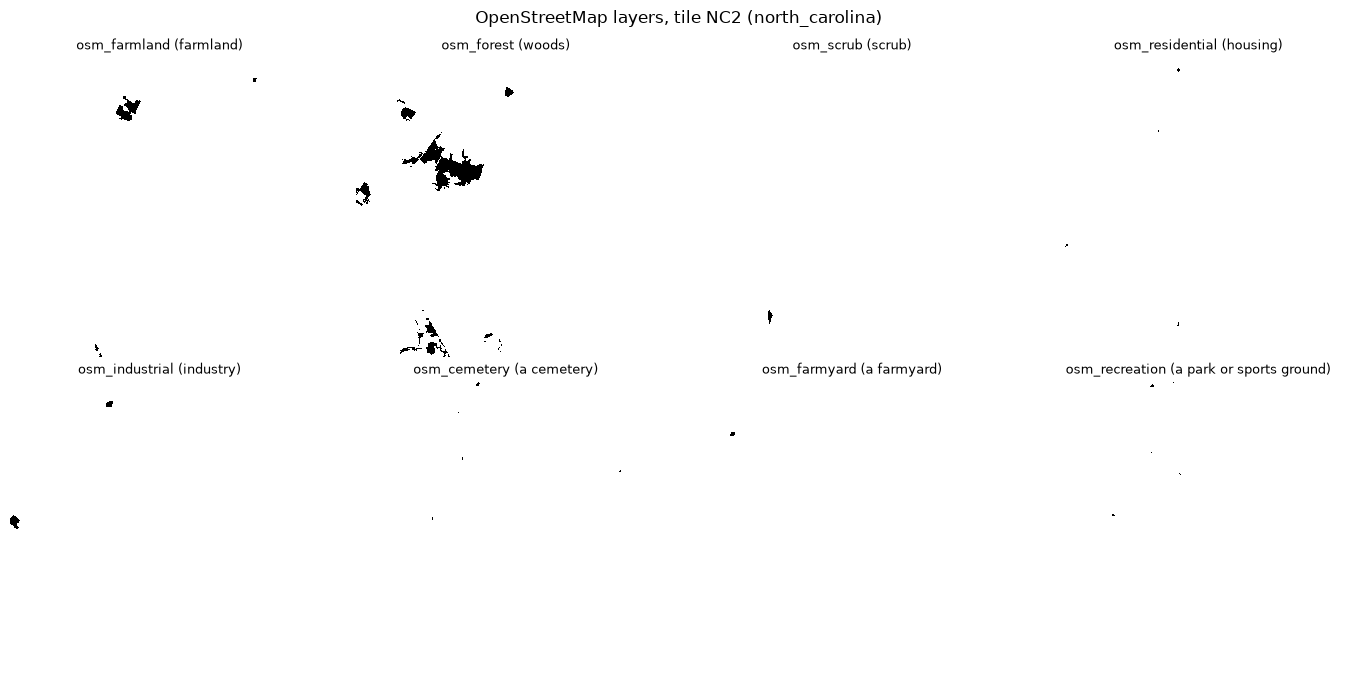

In [4]:
area, name = "north_carolina", "NC2"
z = np.load(OSM_DIR / f"{area}_{name}.npz")
n = round(cfg["grid"]["tile_size_m"] / cfg["grid"]["res_m"])
show = [k for k in USED if np.unpackbits(z[k])[: n * n].any()][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, k in zip(axes.ravel(), show, strict=False):
    ax.imshow(np.unpackbits(z[k])[: n * n].reshape(n, n), cmap="Greys", interpolation="nearest")
    ax.set_title(f"{k} ({VOCAB[k]['words'][0]})", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(show) :]:
    ax.axis("off")
fig.suptitle(f"OpenStreetMap layers, tile {name} ({area})")
fig.tight_layout()
fig.savefig(FIG / "10_osm_layers.png", dpi=110)
print(f"Run time {(time.time() - T_START) / 60:.1f} min")